# 🎓 第6章 第3课：机器学习与过拟合

**本节目标**：理解机器学习在因子研究中的力量与陷阱。

1. 多项式阶数越高，训练误差越低，但测试误差可能变高（过拟合）；
2. 线性模型 vs 随机森林：训练集表现好，不代表样本外好；
3. 金融数据非平稳、小样本、低信噪比——ML 不是万能钥匙。

对应原书第6章机器学习部分。

In [1]:
import sys
from pathlib import Path

def _find_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / 'src' / 'factor_zero').exists():
            return p
    raise FileNotFoundError('找不到仓库根目录，请从仓库内启动 notebook')
ROOT = _find_root()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from factor_zero.research import (
    simulate_random_factors, p_hacking_summary,
    publication_decay_experiment, polynomial_train_test_mse, sentiment_signal,
)
from factor_zero.data import load_ashare_panel
from factor_zero.factors import build_factor_returns
from factor_zero.sorting import long_short_factor, monotonicity_test
from factor_zero.statistics import factor_summary, nw_t_stat

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
print('✅ 环境就绪，开始学习！')

✅ 环境就绪，开始学习！


## 1) 过拟合：高阶多项式记住了噪声

真实关系是“线性 + 正弦 + 噪声”。我们用不同阶数多项式拟合，
比较**训练集 MSE** 和**测试集 MSE**。

In [2]:
mse = polynomial_train_test_mse(degrees=(1, 3, 5, 9, 15), n=200, noise=0.3, seed=42)
mse.round(4)

,degree,train_mse,test_mse
0,1,0.3571,0.3937
1,3,0.1203,0.1217
2,5,0.0699,0.0750
3,9,0.0666,0.0753
4,15,0.0653,0.0768


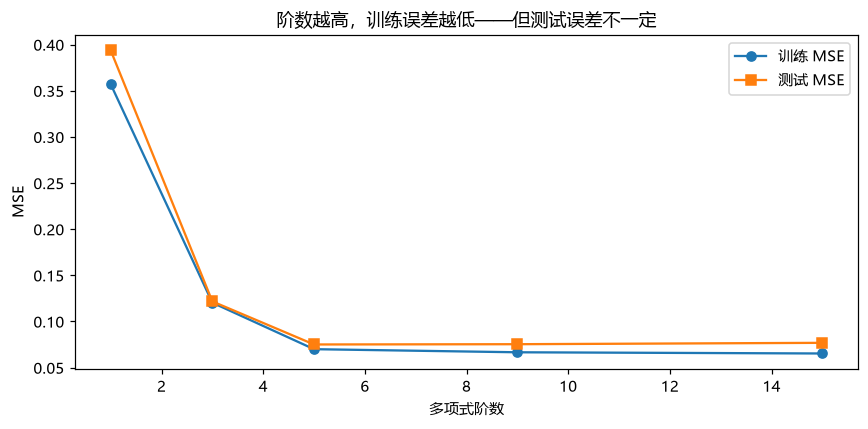

In [3]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(mse['degree'], mse['train_mse'], marker='o', label='训练 MSE')
ax.plot(mse['degree'], mse['test_mse'], marker='s', label='测试 MSE')
ax.set_xlabel('多项式阶数'); ax.set_ylabel('MSE')
ax.set_title('阶数越高，训练误差越低——但测试误差不一定')
ax.legend(); plt.tight_layout(); plt.show()

## 2) 线性回归 vs 随机森林

同一组非线性数据：线性模型可能欠拟合，随机森林可能过拟合。
关键看**测试集**，不是训练集。

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(42)
n = 150
x = np.linspace(-3, 3, n)
y = 0.5 * x + 0.8 * np.sin(1.5 * x) + rng.normal(0, 0.3, n)
X = x.reshape(-1, 1)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=42)

rows = []
for name, model in [
    ('线性回归', LinearRegression()),
    ('随机森林', RandomForestRegressor(n_estimators=300, random_state=42)),
]:
    model.fit(Xtr, ytr)
    rows.append({
        '模型': name,
        '训练 MSE': mean_squared_error(ytr, model.predict(Xtr)),
        '测试 MSE': mean_squared_error(yte, model.predict(Xte)),
    })
pd.DataFrame(rows).set_index('模型').round(4)

,训练 MSE,测试 MSE
模型,,
线性回归,0.3387,0.3507
随机森林,0.0091,0.1078


## 3) 把 ML 用到因子收益预测：小样本 + 非平稳

用滞后一期的因子收益预测下月 MKT。
前 70% 训练、后 30% 测试——这是时间序列，不能随机打乱。
看测试 R²：金融数据里常常很差，甚至为负。

In [5]:
factors = build_factor_returns(load_ashare_panel(), n_groups=10)
features = ['SMB', 'HML', 'WML', 'RMW', 'CMA', 'TURN']
data = factors[features].shift(1).join(factors['MKT']).dropna()
X = data[features].to_numpy(); y = data['MKT'].to_numpy()
split = int(len(data) * 0.7)
Xtr, Xte, ytr, yte = X[:split], X[split:], y[:split], y[split:]

rows = []
for name, model in [
    ('线性回归', LinearRegression()),
    ('随机森林', RandomForestRegressor(n_estimators=300, random_state=42)),
]:
    model.fit(Xtr, ytr)
    rows.append({
        '模型': name,
        '训练 R²': model.score(Xtr, ytr),
        '测试 R²': model.score(Xte, yte),
    })
pd.DataFrame(rows).set_index('模型').round(4)

,训练 R²,测试 R²
模型,,
线性回归,0.1407,-0.0352
随机森林,0.8381,-0.1842


> 🔍 **本例测试 R² 为负**：说明模型在样本外连“均值预测”都不如。
> 金融时间序列信噪比低、非平稳，ML 很容易在训练集上表现很好、样本外失效。


## 4) ML 在因子研究中的问题

| 问题 | 说明 | 对策 |
|---|---|---|
| 过拟合 | 模型记住噪声，样本外失效 | 训练/验证/测试、正则化、简化模型 |
| 非平稳 | 市场结构变化，历史关系失效 | 滚动/扩展窗口、样本外检验 |
| 低信噪比 | 金融收益噪声大，信号弱 | 经济逻辑、因子筛选、集成 |
| 可解释性 | 黑箱难解释 | 线性/树模型、特征重要性、SHAP |
| 数据窥探 | 试了很多模型/参数 | 预注册、多重检验校正、样本外 |

> 机器学习是工具，不是魔法。**先有经济逻辑，再做样本外验证。**

## ✋ 试一试

1. 把多项式阶数加到 30，训练 MSE 和测试 MSE 怎么变？
2. 把随机森林的 `n_estimators` 改成 10，结果稳定吗？
3. 把时间序列切分从 70/30 改成 50/50，测试 R² 怎么变？

## ✅ 本节小结

- 高阶模型/复杂模型在训练集上更好，不代表样本外更好；
- 金融数据小样本、低信噪比、非平稳，ML 很容易过拟合；
- 要用训练/验证/测试、滚动窗口、正则化和经济逻辑；
- 不要用随机打乱的时间序列切分。

> 下一章：因子投资实践——组合优化、Smart Beta、归因。